# 데이터셋 설명

**RentTheRunway Clothing Fit Dataset**
미국 의류 대여 서비스 Rent the Runway 고객이 옷을 입어본 뒤 남긴 리뷰 데이터.
UCSD McAuley Lab에서 공개 ([다운로드](https://mcauleylab.ucsd.edu/public_datasets/data/datasets.html))

> Misra, R., Wan, M., & McAuley, J. (2018). Decomposing fit semantics for product size recommendation in metric spaces. *RecSys 2018*.

**규모**
리뷰 192,544건 · 사용자 105,508명 · 상품 5,850개

**주요 변수**

| 구분 | 변수 | 예시 |
| --- | --- | --- |
| 고객 정보 | 키, 몸무게, 가슴 사이즈, 나이 | 5' 8", 137lbs, 34d, 28 |
| 체형 | body type (고객이 직접 선택, 7종) | hourglass, pear, apple 등 |
| 옷 정보 | 옷 종류, 대여 사이즈 | dress, 14 |
| 결과 | fit (예측 대상) | small / fit / large |
| 기타 | 리뷰 글, 별점, 대여 목적 | "An adorable romper!..." |

**특징**
- 결과가 불균형함: 맞음 약 74%, 작음·큼 각각 약 13%
- 체형별 리뷰 수 차이가 큼: hourglass 55,349건 vs apple 4,877건
- 키·몸무게는 미국 단위(피트·인치, lbs)로 기록되어 변환 필요

In [1]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os, re, json
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/3-2/시각화 학술제"

Mounted at /content/drive


## 1. 데이터 전처리 (논문 2.1)

**처리 기준**
- 체형, 착용 결과(fit), 옷 종류, 사이즈가 빈 행만 삭제한다.
- 키·몸무게·가슴 사이즈·나이의 결측은 그대로 두고 LightGBM이 처리하게 한다. 결측이 하나라도 있는 행을 모두 지우면 체형별 잔존 비율이 71.9~87.3%로 달라져, 비교 대상인 체형 분포가 왜곡되기 때문이다.
- 이상값(나이 15 ~ 80세, 키 140~200cm 범위 밖)은 값이 있을 때만 제거한다.
- 몸무게 36kg 미만 9건은 입력 오류로 보고 결측 처리하고, 리뷰 글까지 같은 중복 25건은 삭제한다.

**결과**: 192,544행 → 177,524행 (체형별 잔존 비율 99.7~99.9%)

In [2]:
BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
df = pd.read_json(f"{BASE}/데이터/원본/renttherunway_final_data.json.gz", lines=True)
print(len(df))

192544


In [3]:
print(df.isna().sum())
print(df['fit'].value_counts())
print(df['body type'].value_counts())
df.head()

fit                   0
user_id               0
bust size         18411
item_id               0
weight            29982
rating               82
rented for           10
review_text           0
body type         14637
review_summary        0
category              0
height              677
size                  0
age                 960
review_date           0
dtype: int64
fit
fit      142058
small     25779
large     24707
Name: count, dtype: int64
body type
hourglass            55349
athletic             43667
pear                 22135
petite               22131
full bust            15006
straight & narrow    14742
apple                 4877
Name: count, dtype: int64


,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10.0,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28.0,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10.0,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36.0,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10.0,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116.0,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8.0,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34.0,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10.0,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27.0,"September 26, 2016"


In [6]:
# ── 단위 변환: 피트·인치 → cm, lbs → kg, 가슴 사이즈 → 밴드 + 컵 ──
df.columns = df.columns.str.replace(' ', '_')
df['review_id'] = range(len(df))

def to_cm(h):
    m = re.match(r"(\d+)' (\d+)\"", str(h))
    return (int(m[1]) * 12 + int(m[2])) * 2.54 if m else np.nan

df['height_cm'] = df['height'].apply(to_cm)
df['weight_kg'] = pd.to_numeric(df['weight'].str.replace('lbs', ''), errors='coerce') * 0.4536

bust = df['bust_size'].str.extract(r'(\d+)(.+)')
df['bust_band'] = pd.to_numeric(bust[0], errors='coerce')
df['cup'] = bust[1]

df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['label'] = df['fit'].map({'small': 0, 'fit': 1, 'large': 2})

df[['height', 'height_cm', 'weight', 'weight_kg', 'bust_size', 'bust_band', 'cup']].head()

,height,height_cm,weight,weight_kg,bust_size,bust_band,cup
0,"5' 8""",172.72,137lbs,62.1432,34d,34.0,d
1,"5' 6""",167.64,132lbs,59.8752,34b,34.0,b
2,"5' 4""",162.56,NaN,NaN,NaN,NaN,NaN
3,"5' 5""",165.10,135lbs,61.2360,34c,34.0,c
4,"5' 9""",175.26,145lbs,65.7720,34b,34.0,b


In [8]:
# ── 필수 정보가 빈 행만 삭제하고 신체 치수 결측은 유지 ──
before = df['body_type'].value_counts()

must = ['body_type', 'label', 'category', 'size']
clean2 = df.dropna(subset=must)

clean2 = clean2[clean2['age'].isna() | clean2['age'].between(15, 80)]
clean2 = clean2[clean2['height_cm'].isna() | clean2['height_cm'].between(140, 200)]

dup_cols = [c for c in clean2.columns if c != 'review_id']
clean2 = clean2.drop_duplicates(subset=dup_cols)

check2 = pd.DataFrame({'전처리 전': before, '전처리 후': clean2['body_type'].value_counts()})
check2['남은 비율'] = (check2['전처리 후'] / check2['전처리 전']).round(3)
print(len(clean2))
display(check2)

177549


,전처리 전,전처리 후,남은 비율
body_type,,,
apple,4877,4867,0.998
athletic,43667,43603,0.999
full bust,15006,14981,0.998
hourglass,55349,55233,0.998
pear,22135,22075,0.997
petite,22131,22077,0.998
straight & narrow,14742,14713,0.998


In [9]:
# ── 컵 사이즈를 숫자로 바꾸기 (clean2 기준) ──
cup_order = {'aa': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'd+': 4.5, 'dd': 5,
             'ddd/e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'j': 11}
clean2['cup_num'] = clean2['cup'].map(cup_order)

print(clean2['cup_num'].isna().sum(), clean2['cup'].isna().sum())

12292 12292


In [10]:
# ── 개수가 적은 옷 종류를 '기타'로 묶기 (clean2 기준) ──
cat_counts = clean2['category'].value_counts()
rare = cat_counts[cat_counts < 500].index
clean2['category'] = clean2['category'].where(~clean2['category'].isin(rare), 'other')
print(clean2['category'].value_counts())

category
dress         85556
gown          40860
sheath        17796
shift          5008
jumpsuit       4717
top            4507
other          3708
maxi           3190
romper         2869
jacket         2251
mini           1692
skirt          1415
sweater        1059
coat            915
blazer          726
shirtdress      680
blouse          600
Name: count, dtype: int64


In [12]:
# ── 체형별 기초 통계표 ──

stats = clean2.groupby('body_type').agg(
    리뷰수=('review_id', 'count'),
    사람수=('user_id', 'nunique'))

ratio = pd.crosstab(clean2['body_type'], clean2['fit'], normalize='index').round(3)

stats = stats.join(ratio).sort_values('리뷰수', ascending=False)
display(stats)

,리뷰수,사람수,fit,large,small
body_type,,,,,
hourglass,55233,29743,0.738,0.130,0.132
athletic,43603,23836,0.743,0.120,0.137
petite,22077,12219,0.743,0.131,0.126
pear,22075,11899,0.729,0.145,0.127
full bust,14981,8029,0.718,0.140,0.142
straight & narrow,14713,7488,0.746,0.121,0.134
apple,4867,2807,0.716,0.136,0.148


In [13]:
# ── 사람 단위로 학습용·보정용·시험용 나누기 ──
# 랜덤 시드를 42로 고정해서 누가 돌려도 같은 결과가 나오게 함
rng = np.random.default_rng(42)

# 정리된 데이터에 있는 사람(user_id) 목록을 중복 없이 뽑고 무작위로 섞음
users = clean2['user_id'].unique()
rng.shuffle(users)

# 섞인 순서대로 앞 60%는 학습용, 다음 20%는 보정용, 나머지 20%는 시험용
n = len(users)
split = pd.DataFrame({'user_id': users})
split['set'] = 'test'
split.loc[:int(n * 0.6) - 1, 'set'] = 'train'
split.loc[int(n * 0.6):int(n * 0.8) - 1, 'set'] = 'cal'

# 분할명단 저장
split.to_csv(f"{BASE}/데이터/정리/분할명단.csv", index=False)

# 사람 수가 대략 6:2:2로 나뉘었는지 확인
print(split['set'].value_counts())

# 리뷰 수 기준으로도 비율 확인 (사람마다 리뷰 수가 달라서 정확히 6:2:2는 아닐 수 있음)
print(clean2.merge(split, on='user_id')['set'].value_counts(normalize=True).round(3))

set
train    57612
test     19205
cal      19204
Name: count, dtype: int64
set
train    0.596
test     0.203
cal      0.201
Name: proportion, dtype: float64


In [14]:
# ── 정리된 데이터 저장 ──
keep = ['review_id', 'user_id', 'item_id', 'height_cm', 'weight_kg', 'bust_band', 'cup_num',
        'body_type', 'category', 'size', 'age', 'fit', 'label', 'review_text']
clean2[keep].to_csv(f"{BASE}/데이터/정리/정리데이터.csv", index=False)
print("저장 완료")

저장 완료


In [15]:
# 정리데이터 다시 읽기
# keep_default_na=False: "N/A", "None" 같은 글을 빈칸으로 바꾸지 않음
# 진짜로 비어 있는 칸만 빈칸으로 처리
path = f"{BASE}/데이터/정리/정리데이터.csv"
c = pd.read_csv(path, keep_default_na=False, na_values=[''])

# 1. 몸무게 36kg 미만은 입력 실수로 보고 빈칸으로 바꿈
print("바꿀 몸무게 개수:", (c['weight_kg'] < 36).sum())
c.loc[c['weight_kg'] < 36, 'weight_kg'] = np.nan

# 2. review_id만 다르고 나머지가 똑같은 중복 리뷰는 하나만 남김
dup_cols = [col for col in c.columns if col != 'review_id']
print("지울 중복 개수:", c.duplicated(subset=dup_cols).sum())
c = c.drop_duplicates(subset=dup_cols)

# 3. 다시 저장
print(len(c))
c.to_csv(path, index=False)

바꿀 몸무게 개수: 9
지울 중복 개수: 25
177524


## 2. 모델 학습 (논문 2.1)

| 항목 | 내용 |
| --- | --- |
| 모델 | LightGBM 다중 분류 (작음 0 · 맞음 1 · 큼 2) |
| 신체 정보 | 키, 몸무게, 가슴 둘레, 컵, 체형, 나이 |
| 의류 특성 | 옷 종류, 사이즈, 상품별 작음·큼 비율, 상품 리뷰 수, 상품 평균 대비 사이즈 차이 |
| 불균형 처리 | `class_weight='balanced'` (맞음이 74%라 작음·큼의 가중치가 커짐) |
| 조기 종료 | 학습용 중 10%(사람 단위)를 검증용으로 두고, 검증 손실도 같은 가중치로 계산 |
| 분할 | 사람 단위 학습용 60% · 보정용 20% · 시험용 20%, 시드 42 |

상품별 작음·큼 비율은 정답 정보를 쓰므로, 학습용은 사람 단위 5-fold로 나눠 자기 fold를 뺀 나머지로 계산하고 보정용·시험용은 학습용 전체로 계산한다.

In [18]:
# ── 라이브러리, 경로, 데이터 불러오기 ──
import lightgbm as lgb
from sklearn.utils.class_weight import compute_sample_weight

CLEAN_PATH = f"{BASE}/데이터/정리/정리데이터.csv"
SPLIT_PATH = f"{BASE}/데이터/정리/분할명단.csv"
PRED_DIR   = f"{BASE}/예측결과"
os.makedirs(PRED_DIR, exist_ok=True)

data = pd.read_csv(CLEAN_PATH, keep_default_na=False, na_values=[''])
split = pd.read_csv(SPLIT_PATH)
data = data.merge(split, on='user_id', how='left')
print(len(data), data['set'].isna().sum())   # 177524 0

# 신체 정보 + 옷 종류·사이즈 (user_id, item_id는 개인·상품을 외우지 않도록 제외)
features = ['height_cm', 'weight_kg', 'bust_band', 'cup_num',
            'body_type', 'category', 'size', 'age']

for col in ['body_type', 'category']:
    data[col] = data[col].astype('category')

train = data[data['set'] == 'train']
cal   = data[data['set'] == 'cal']
test  = data[data['set'] == 'test']
print(len(train), len(cal), len(test))

# 조기 종료용 검증 사용자: 학습용 사용자 중 10%
rng = np.random.default_rng(42)
tr_users = train['user_id'].unique()
val_users = rng.choice(tr_users, size=int(len(tr_users) * 0.1), replace=False)

177524 0
105807 35696 36021


In [20]:
# ── 의류 특성 만들기 (상품별 작음·큼 비율 등) ──
from sklearn.model_selection import GroupKFold

m = 20   # 리뷰가 적은 옷은 전체 평균 쪽으로 당겨서 값이 튀지 않게 함
prior_s = (train['label'] == 0).mean()
prior_l = (train['label'] == 2).mean()

def item_stats(src):
    # 옷마다 작음·큼 비율(보정값)과 평균 사이즈, 리뷰 수를 계산
    gi = src.groupby('item_id').agg(n=('label', 'size'),
                                     s=('label', lambda x: (x == 0).sum()),
                                     l=('label', lambda x: (x == 2).sum()),
                                     size_mean=('size', 'mean'))
    gi['item_small'] = (gi['s'] + m * prior_s) / (gi['n'] + m)
    gi['item_large'] = (gi['l'] + m * prior_l) / (gi['n'] + m)
    gi['item_n'] = gi['n']
    return gi[['item_small', 'item_large', 'size_mean', 'item_n']]

def add_item_feats(df, stats):
    out = df.join(stats, on='item_id')
    # 처음 보는 옷은 전체 평균으로 채움
    out['item_small'] = out['item_small'].fillna(prior_s)
    out['item_large'] = out['item_large'].fillna(prior_l)
    out['item_n'] = out['item_n'].fillna(0)
    # 이 사람이 빌린 사이즈가 그 옷의 평균 사이즈보다 얼마나 큰지
    out['size_diff'] = out['size'] - out['size_mean']
    return out.drop(columns='size_mean')

# 학습용: 사람 단위 5등분, 각 덩어리는 나머지로 계산한 값 사용 (정답 미리 보기 방지)
parts = []
for tr_idx, va_idx in GroupKFold(n_splits=5).split(train, groups=train['user_id']):
    stats = item_stats(train.iloc[tr_idx])
    parts.append(add_item_feats(train.iloc[va_idx], stats))
train2 = pd.concat(parts).loc[train.index]

# 보정용·시험용: 학습용 전체로 계산한 값 사용
stats_all = item_stats(train)
cal2 = add_item_feats(cal, stats_all)
test2 = add_item_feats(test, stats_all)

features2 = features + ['item_small', 'item_large', 'item_n', 'size_diff']
display(train2[features2].head())

,height_cm,weight_kg,bust_band,cup_num,body_type,category,size,age,item_small,item_large,item_n,size_diff
2,165.10,61.2360,34.0,3.0,pear,dress,8,34.0,0.049403,0.190778,1026.0,-8.741715
3,175.26,65.7720,34.0,2.0,athletic,gown,12,27.0,0.052514,0.050765,50.0,0.940000
5,160.02,50.8032,34.0,3.0,hourglass,dress,4,27.0,0.127429,0.121596,1.0,-22.000000
7,167.64,NaN,36.0,4.0,full bust,gown,21,27.0,0.140753,0.042555,134.0,6.985075
8,160.02,51.7104,32.0,2.0,petite,gown,1,33.0,0.137840,0.030357,130.0,-12.223077


In [21]:
# 지금 결과를 재현할 수 있게 덩어리 배정과 라이브러리 버전 저장
import sklearn, lightgbm
fold_map = []
for f, (_, va_idx) in enumerate(GroupKFold(n_splits=5).split(train, groups=train['user_id'])):
    fold_map.append(pd.DataFrame({'user_id': train.iloc[va_idx]['user_id'].unique(), 'fold': f}))
pd.concat(fold_map).to_csv(f"{BASE}/데이터/정리/학습용_fold배정.csv", index=False)

with open(f"{BASE}/결과표/v2/버전.txt", 'w') as fp:
    fp.write(f"scikit-learn {sklearn.__version__}\nlightgbm {lightgbm.__version__}\npandas {pd.__version__}\nnumpy {np.__version__}\n")
print("저장 완료")

저장 완료


In [22]:
# ── 모델 학습 ──
tr2 = train2[~train2['user_id'].isin(val_users)]
val2 = train2[train2['user_id'].isin(val_users)]
val_w2 = compute_sample_weight('balanced', val2['label'])   # 검증 손실도 학습과 같은 가중치로

model2 = lgb.LGBMClassifier(objective='multiclass', n_estimators=3000, learning_rate=0.1,
                            num_leaves=31, class_weight='balanced', random_state=42, verbose=-1)
model2.fit(tr2[features2], tr2['label'],
           eval_set=[(val2[features2], val2['label'])], eval_sample_weight=[val_w2],
           callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
print("사용된 나무 수:", model2.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 0.838947
Early stopping, best iteration is:
[64]	valid_0's multi_logloss: 0.837546
사용된 나무 수: 64


In [23]:
# ── 보정용·시험용 예측 확률(p)과 원점수(z) 저장 ──
def save_preds_v2(df, name):
    prob = model2.predict_proba(df[features2])
    raw = model2.predict(df[features2], raw_score=True)
    out = df[['review_id', 'user_id', 'body_type', 'height_cm', 'weight_kg', 'label']].copy()
    out['p_small'], out['p_fit'], out['p_large'] = prob[:, 0], prob[:, 1], prob[:, 2]
    out['z_small'], out['z_fit'], out['z_large'] = raw[:, 0], raw[:, 1], raw[:, 2]
    save_path = f"{PRED_DIR}/{name}_예측확률_v2.csv"
    out.to_csv(save_path, index=False)
    print(save_path, "저장 완료:", len(out), "줄")

save_preds_v2(cal2, '보정용')
save_preds_v2(test2, '시험용')

/content/drive/MyDrive/3-2/시각화 학술제/예측결과/보정용_예측확률_v2.csv 저장 완료: 35696 줄
/content/drive/MyDrive/3-2/시각화 학술제/예측결과/시험용_예측확률_v2.csv 저장 완료: 36021 줄


## 3. 확률 보정 (논문 2.2)

클래스 가중치 때문에 모델은 작음·큼 확률을 실제보다 크게 낸다. 이를 두 단계로 바로잡는다.

1. **사전확률 복원**: 원점수 z에 학습용의 실제 결과 비율(작음·맞음·큼)의 로그를 더한다.
2. **온도 스케일링**: 보정용 데이터에서 음의 로그우도가 최소가 되는 T 하나를 찾아 z를 T로 나눈다.

보정 확률 = softmax((z + log 사전확률) / T). T는 보정용에서만 찾고, 시험용에는 그대로 적용한다.
보정 정도는 ECE(15구간)로 평가한다.

In [24]:
# ── 저장된 예측 파일 불러오기 ──
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import softmax

FIG_DIR = f"{BASE}/그래프/v2"
RES_DIR = f"{BASE}/결과표/v2"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

pt = pd.read_csv(f"{PRED_DIR}/시험용_예측확률_v2.csv")   # 시험용
pc = pd.read_csv(f"{PRED_DIR}/보정용_예측확률_v2.csv")   # 보정용

# 학습용 결과 비율 (사전확률 복원에 사용)
data_raw = pd.read_csv(CLEAN_PATH, keep_default_na=False, na_values=[''])
train_label = data_raw.merge(split, on='user_id').query("set == 'train'")['label']

order = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
pcols, zcols, qcols = ['p_small', 'p_fit', 'p_large'], ['z_small', 'z_fit', 'z_large'], ['q_small', 'q_fit', 'q_large']
print(len(pt), len(pc))

36021 35696


In [25]:
# ── 사전확률 복원 + 온도 스케일링 ──
def ece(p, y, n_bins=15):
    # 예측 확률(가장 큰 확률)과 실제 정답 비율의 구간별 차이를 구간 비중으로 가중 평균
    conf, correct = p.max(1), (p.argmax(1) == y)
    bins = np.linspace(0, 1, n_bins + 1); total = 0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum(): total += abs(conf[m].mean() - correct[m].mean()) * m.mean()
    return total

# 1단계 : 사전확률 복원
log_prior = np.log(train_label.value_counts(normalize=True).sort_index().values)

# 2단계 : 보정용 데이터로 T 찾기
zc, yc = pc[zcols].values + log_prior, pc['label'].values
nll = lambda T: -np.log(softmax(zc / T, axis=1)[np.arange(len(yc)), yc] + 1e-12).mean()
T = minimize_scalar(nll, bounds=(0.05, 10), method='bounded').x
print("T:", round(T, 4))

pt[qcols] = softmax((pt[zcols].values + log_prior) / T, axis=1)
pc[qcols] = softmax((pc[zcols].values + log_prior) / T, axis=1)

# 체형별 ECE 보정 전후
rows = []
for bt in order + ['전체']:
    d = pt if bt == '전체' else pt[pt['body_type'] == bt]
    rows.append({'body_type': bt, 'ECE_보정전': ece(d[pcols].values, d['label'].values),
                 'ECE_보정후': ece(d[qcols].values, d['label'].values)})
ece_df = pd.DataFrame(rows).set_index('body_type')
display(ece_df.round(3))

T: 1.0166


,ECE_보정전,ECE_보정후
body_type,,
hourglass,0.157,0.004
athletic,0.140,0.010
pear,0.163,0.011
petite,0.136,0.026
full bust,0.149,0.021
straight & narrow,0.156,0.014
apple,0.162,0.033
전체,0.149,0.003


## 4. 기준값 설정: Conformal Prediction (논문 2.2)

보정된 확률로 후보 사이즈 묶음을 만들고, 실제 결과가 묶음에 들어갈 비율(포함률)이 90%가 되도록 기준값을 정한다 (alpha = 0.1).

- 비적합 점수 = 1 − (실제 결과에 준 보정 확률)
- 기준값 = 보정용 점수의 ⌈(n+1)(1−alpha)⌉/n 분위수
- 후보 포함 규칙: 1 − (그 결과의 보정 확률) ≤ 기준값

두 방식을 비교한다.
1. **공통 기준값**: 모든 리뷰에 기준값 하나
2. **체형 × 결과별 기준값**: 체형 7종 × 착용 결과 3종, 21개 집단마다 기준값을 따로 계산

평가 지표는 착용 결과별·체형별 포함률과 평균 후보 수다.

In [26]:
# ── 공통 기준값 vs 체형×결과별 기준값 ──
alpha = 0.1
q_cal, y_cal, bt_cal = pc[qcols].values, pc['label'].values, pc['body_type'].values
q_test, y_test, bt_test = pt[qcols].values, pt['label'].values, pt['body_type'].values

def threshold(scores, alpha):
    n = len(scores); level = min(1, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method='higher')

# [공통 기준값]
t_all = threshold(1 - q_cal[np.arange(len(y_cal)), y_cal], alpha)
set_all = (1 - q_test) <= t_all

# [체형×결과별 기준값]
t_bk = {(bt, k): threshold(1 - q_cal[(bt_cal == bt) & (y_cal == k), k], alpha)
        for bt in order for k in [0, 1, 2]}
t_mat = np.array([[t_bk[(bt, k)] for k in [0, 1, 2]] for bt in bt_test])
set_bk = (1 - q_test) <= t_mat
print("공통 기준값:", round(t_all, 4))

def coverage_by_label(sets, name):
    # 체형별·착용 결과별 포함률
    d = pd.DataFrame({'body_type': bt_test, 'label': y_test,
                      'covered': sets[np.arange(len(y_test)), y_test]})
    t = d.pivot_table(index='body_type', columns='label', values='covered')
    t.columns = [f'{name}_작음', f'{name}_맞음', f'{name}_큼']
    return t

cov = coverage_by_label(set_all, '공통').join(coverage_by_label(set_bk, '체형결과별')).loc[order]
cov['공통_후보수'] = pd.Series(set_all.sum(1)).groupby(bt_test).mean()
cov['체형결과별_후보수'] = pd.Series(set_bk.sum(1)).groupby(bt_test).mean()
display(cov.round(3))

# 후보 1·2·3개 비율 (체형×결과별 기준값)
dist = pd.crosstab(bt_test, set_bk.sum(1), normalize='index').loc[order]
dist.columns = [f'후보 {c}개' for c in dist.columns]
display(dist.round(3))

공통 기준값: 0.8359


,공통_작음,공통_맞음,공통_큼,체형결과별_작음,체형결과별_맞음,체형결과별_큼,공통_후보수,체형결과별_후보수
body_type,,,,,,,,
hourglass,0.621,1.0,0.641,0.910,0.905,0.891,1.515,2.090
athletic,0.658,1.0,0.596,0.923,0.896,0.889,1.486,2.009
pear,0.604,1.0,0.658,0.897,0.898,0.880,1.538,2.059
petite,0.589,1.0,0.604,0.881,0.886,0.938,1.511,2.075
full bust,0.686,1.0,0.696,0.904,0.893,0.936,1.576,2.014
straight & narrow,0.663,1.0,0.587,0.929,0.895,0.921,1.451,2.153
apple,0.645,1.0,0.708,0.868,0.903,0.933,1.607,2.185


,후보 1개,후보 2개,후보 3개
row_0,,,
hourglass,0.169,0.572,0.259
athletic,0.205,0.582,0.214
pear,0.182,0.578,0.240
petite,0.185,0.555,0.260
full bust,0.203,0.580,0.217
straight & narrow,0.174,0.500,0.327
apple,0.143,0.529,0.328


## 5. 결과 저장

보정 확률, 후보 묶음, 설정값(T, 사전확률, 기준값)을 저장한다. 웹 시연(app.py)도 이 설정값을 그대로 쓴다.

In [27]:
# ── 결과표·보정 확률·설정값 저장 ──
tables = {'3_ECE_보정전후': ece_df,
          '6_conformal_포함률_후보수': cov,
          '7_후보개수_분포': dist}
for name, d in tables.items():
    d.round(4).to_csv(f"{RES_DIR}/{name}.csv", encoding='utf-8-sig')
with pd.ExcelWriter(f"{RES_DIR}/논문결과_v2.xlsx") as writer:
    for name, d in tables.items():
        d.round(4).to_excel(writer, sheet_name=name[:31])

# 시험용: 보정 확률 + 후보 포함 여부(1이면 포함)
test_out = pt[['review_id', 'user_id', 'body_type', 'label'] + qcols].copy()
test_out[['공통_작음', '공통_맞음', '공통_큼']] = set_all.astype(int)
test_out[['체형결과별_작음', '체형결과별_맞음', '체형결과별_큼']] = set_bk.astype(int)
test_out['공통_후보수'] = set_all.sum(1)
test_out['체형결과별_후보수'] = set_bk.sum(1)
test_out.to_csv(f"{PRED_DIR}/시험용_보정확률_v2.csv", index=False)
pc[['review_id', 'user_id', 'body_type', 'label'] + qcols].to_csv(
    f"{PRED_DIR}/보정용_보정확률_v2.csv", index=False)

settings = {
    '모델': 'LightGBM v2 (신체 정보 + 의류 특성)',
    '시드': 42,
    'temperature_T': float(T),
    '학습용_정답비율': {'작음': float(np.exp(log_prior[0])),
                       '맞음': float(np.exp(log_prior[1])),
                       '큼': float(np.exp(log_prior[2]))},
    'conformal_alpha': alpha,
    '공통_기준값': float(t_all),
    '체형결과별_기준값': {f"{bt}_{['작음', '맞음', '큼'][k]}": float(v) for (bt, k), v in t_bk.items()},
}
with open(f"{RES_DIR}/설정값.json", 'w', encoding='utf-8') as f:
    json.dump(settings, f, ensure_ascii=False, indent=2)
print("저장 완료")

저장 완료


## 6. 결과 (논문 3장)

### 6-1. 확률 보정 단계별 ECE (논문 3.1 표)

In [28]:
raw = pd.read_csv(f"{BASE}/예측결과/시험용_예측확률_v2.csv")
cfg = json.load(open(f"{BASE}/결과표/v2/설정값.json", encoding='utf-8'))
T = cfg['temperature_T']
prior = np.array([cfg['학습용_정답비율'][k] for k in ['작음', '맞음', '큼']])
Z = raw[['z_small', 'z_fit', 'z_large']].values
y = raw['label'].values

def ece(prob, y, n_bins=15):
    conf, correct = prob.max(1), (prob.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1); total = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

steps = {'보정 전':                       softmax(Z, axis=1),
         '사전확률 복원':                  softmax(Z + np.log(prior), axis=1),
         '사전확률 복원 + 온도 스케일링':    softmax((Z + np.log(prior)) / T, axis=1)}

rows = []
for name, p in steps.items():
    by_bt = [ece(p[raw['body_type'] == b], y[raw['body_type'] == b]) for b in raw['body_type'].unique()]
    rows.append({'단계': name, '전체 ECE': f'{ece(p, y):.3f}',
                 '체형별 ECE': f'{min(by_bt):.3f}~{max(by_bt):.3f}'})

table = pd.DataFrame(rows).set_index('단계')
display(table)
table.to_csv(f"{BASE}/결과표/v2/표_확률보정단계별ECE.csv", encoding='utf-8-sig')

,전체 ECE,체형별 ECE
단계,,
보정 전,0.149,0.136~0.163
사전확률 복원,0.006,0.005~0.030
사전확률 복원 + 온도 스케일링,0.003,0.004~0.033


### 6-2. 확률 보정 전후 신뢰도 곡선 (논문 3.1 그림)

ECE 보정 전 0.149 / 보정 후 0.003


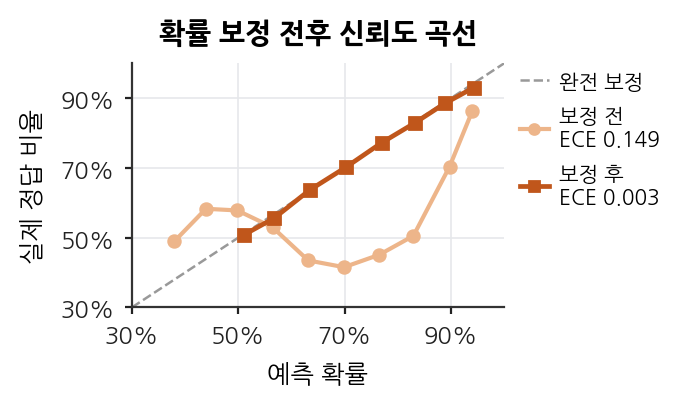

In [31]:
raw = pd.read_csv(f"{BASE}/예측결과/시험용_예측확률_v2.csv")   # 보정 전 확률 p_*
cal = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")   # 보정 후 확률 q_*
y_raw, y_cal = raw['label'].values, cal['label'].values

# 15구간 신뢰도 계산 (논문과 같은 방식)
def reliability(prob, y, n_bins=15, min_n=30):
    conf, correct = prob.max(1), (prob.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys, ece = [], [], 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
        if m.sum() >= min_n:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return np.array(xs), np.array(ys), ece

xb, yb, eb = reliability(raw[['p_small', 'p_fit', 'p_large']].values, y_raw)
xa, ya, ea = reliability(cal[['q_small', 'q_fit', 'q_large']].values, y_cal)
print('ECE 보정 전', round(eb, 3), '/ 보정 후', round(ea, 3))   # 0.149 / 0.003 이면 정상

# ── 2단 편집 한 칸 크기: 범례 포함 최종 약 8.5 × 5.2cm ──
FIG_W_CM = 6.1
W = FIG_W_CM / 2.54

plt.rcParams.update({
    'pdf.fonttype': 42, 'figure.dpi': 200, 'savefig.dpi': 650,
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 7.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8,
})
C_BEFORE, C_AFTER = '#EDB58A', '#C0561B'

fig, ax = plt.subplots(figsize=(W, W * 0.66))
ax.plot([0, 1], [0, 1], ls='--', color='#999999', lw=0.9, label='완전 보정', zorder=1)
ax.plot(xb, yb, marker='o', ms=4.2, lw=1.5, color=C_BEFORE,
        label=f'보정 전\nECE {eb:.3f}', zorder=2)
ax.plot(xa, ya, marker='s', ms=4.0, lw=1.7, color=C_AFTER,
        label=f'보정 후\nECE {ea:.3f}', zorder=3)

ticks = [0.3, 0.5, 0.7, 0.9]
ax.set_xlim(0.3, 1.0); ax.set_ylim(0.3, 1.0)
ax.set_xticks(ticks); ax.set_xticklabels([f'{int(t*100)}%' for t in ticks])
ax.set_yticks(ticks); ax.set_yticklabels([f'{int(t*100)}%' for t in ticks])
ax.set_xlabel('예측 확률', labelpad=5)
ax.set_ylabel('실제 정답 비율', labelpad=6)
ax.set_title('확률 보정 전후 신뢰도 곡선', pad=8, fontweight='bold')
ax.grid(True, color='#E6E8EB', lw=0.6); ax.set_axisbelow(True)
ax.tick_params(length=2.5, width=0.8, colors='#222222')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False,
          handlelength=1.4, handletextpad=0.5, labelspacing=0.7, borderaxespad=0,
          markerscale=0.85)

fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.png", dpi=650, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_신뢰도곡선.tiff", dpi=650, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

### 6-3. 기준값 방식에 따른 착용 결과별 포함률 (논문 3.2 그림)

  group  common  group_th
0    전체  0.9022    0.8998
1    작음  0.6342    0.9077
2    맞음  0.9999    0.8977
3     큼  0.6337    0.9035


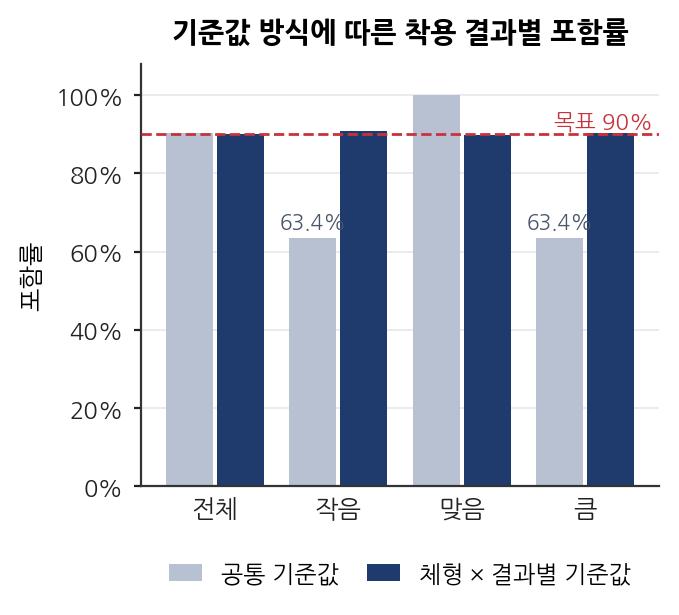

In [32]:
cal = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")
FIG_DIR = f"{BASE}/그래프/v2"
OUT = {0: '작음', 1: '맞음', 2: '큼'}

# 전체 + 착용 결과별 포함률
cond = [cal['label'] == k for k in OUT]
rows = [{'group': '전체',
         'common': np.select(cond, [cal[f'공통_{v}'] for v in OUT.values()]).mean(),
         'group_th': np.select(cond, [cal[f'체형결과별_{v}'] for v in OUT.values()]).mean()}]
for k, v in OUT.items():
    d = cal[cal['label'] == k]
    rows.append({'group': v, 'common': d[f'공통_{v}'].mean(),
                 'group_th': d[f'체형결과별_{v}'].mean()})
res = pd.DataFrame(rows)
print(res.round(4))

# ── 논문에 들어갈 실제 크기로 그리기 ──
FIG_W_CM = 8.5          # 2단 편집 한 칸 기준
W = FIG_W_CM / 2.54

plt.rcParams.update({
    'pdf.fonttype': 42, 'figure.dpi': 200, 'savefig.dpi': 650,
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 9, 'ytick.labelsize': 8.5, 'legend.fontsize': 8.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'axes.titleweight': 'bold',
})
C_COMMON, C_GROUP, C_GOAL = '#B7C1D1', '#1F3B6E', '#C8323C'

fig, ax = plt.subplots(figsize=(W, W * 0.82))
w = 0.38; x = np.arange(len(res))
b1 = ax.bar(x - w/2 - 0.015, res['common'],   w, color=C_COMMON, label='공통 기준값')
b2 = ax.bar(x + w/2 + 0.015, res['group_th'], w, color=C_GROUP,  label='체형 × 결과별 기준값')
ax.axhline(0.9, color=C_GOAL, ls='--', lw=1.0, zorder=3)
ax.text(len(res) - 0.45, 0.905, '목표 90%', ha='right', va='bottom', fontsize=8, color=C_GOAL)

# 목표선과 겹치지 않는 낮은 막대에만 수치 표시
for bars, c in [(b1, '#4A5568'), (b2, C_GROUP)]:
    for b in bars:
        v = b.get_height()
        if v < 0.85:
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v*100:.1f}%',
                    ha='center', va='bottom', fontsize=7.5, color=c)

ax.set_ylim(0, 1.08)
ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.set_yticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xticks(x); ax.set_xticklabels(res['group'])
ax.set_xlim(-0.6, len(res) - 0.4)
ax.set_ylabel('포함률')
ax.set_title('기준값 방식에 따른 착용 결과별 포함률', pad=8, fontweight='bold')
ax.yaxis.grid(True, color='#E6E8EB', lw=0.6); ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0, pad=4, colors='#222222')
ax.tick_params(axis='y', length=2.5, width=0.8, colors='#222222')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False,
          handlelength=1.4, columnspacing=1.2)

fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.pdf", bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.png", dpi=650, bbox_inches='tight')
fig.savefig(f"{FIG_DIR}/그림_착용결과별포함률.tiff", dpi=650, bbox_inches='tight',
            pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

### 6-4. 3.2 본문 보조 수치

체형별 작은 옷·큰 옷 포함률 범위, pear 값, 평균 후보 수, 21개 집단 간 포함률 격차.

In [33]:
cal_out = pd.read_csv(f"{BASE}/예측결과/시험용_보정확률_v2.csv")
OUT = {0: '작음', 1: '맞음', 2: '큼'}
yy = cal_out['label'].values
hit = {m: np.select([yy == k for k in OUT], [cal_out[f'{m}_{v}'] for v in OUT.values()])
       for m in ['공통', '체형결과별']}

cells21 = {m: pd.Series(h).groupby([cal_out['body_type'], cal_out['label']]).mean() for m, h in hit.items()}
for m in ['공통', '체형결과별']:
    c = cells21[m].unstack()
    print(f"[{m}] 작은 옷 {c[0].min():.1%}~{c[0].max():.1%}, 큰 옷 {c[2].min():.1%}~{c[2].max():.1%}, "
          f"pear 작은 옷 {c.loc['pear', 0]:.1%}, 21개 집단 격차 {(cells21[m].max() - cells21[m].min())*100:.1f}%p, "
          f"평균 후보 수 {cal_out[f'{m}_후보수'].mean():.2f}개")

[공통] 작은 옷 58.9%~68.6%, 큰 옷 58.7%~70.8%, pear 작은 옷 60.4%, 21개 집단 격차 41.3%p, 평균 후보 수 1.51개
[체형결과별] 작은 옷 86.8%~92.9%, 큰 옷 88.0%~93.8%, pear 작은 옷 89.7%, 21개 집단 격차 6.9%p, 평균 후보 수 2.07개


In [34]:
import pandas as pd
BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
d = pd.read_csv(f"{BASE}/데이터/정리/정리데이터.csv", keep_default_na=False, na_values=[''])
d.to_csv(f"{BASE}/데이터/정리/정리데이터.csv.gz", index=False, compression='gzip')